<a href="https://colab.research.google.com/github/itsanuragkumar/Safe_Pass-realmain/blob/main/unit2alogorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving credit_score_data.csv to credit_score_data.csv


In [ ]:
df = pd.read_csv("credit_score_data.csv")

print(df.head())
print("\nShape:", df.shape)

  income_stability  average_eligible_emi  average_usable_salary  \
0           STABLE              50390.18                 141932   
1      FLUCTUATING              78874.08                 262709   
2           STABLE              35176.42                  77435   
3           STABLE             113193.83                 261995   
4           STABLE             123516.80                 212283   

   average_monthly_credit          employer_category  employment_tenure_years  \
0               363258.21   Category B (Private Ltd)                     2.95   
1               784034.81   Category B (Private Ltd)                     4.73   
2               169182.24  Category A (MNC/Govt/PSU)                     4.68   
3               325941.81   Category B (Private Ltd)                     0.17   
4               592196.27   Category B (Private Ltd)                    12.75   

   average_month_end_balance  bounce_count  gambling_transaction_count  \
0                    7285.71        

In [ ]:
print(df.columns)

Index(['income_stability', 'average_eligible_emi', 'average_usable_salary',
       'average_monthly_credit', 'employer_category',
       'employment_tenure_years', 'average_month_end_balance', 'bounce_count',
       'gambling_transaction_count', 'active_loans_count', 'has_credit_card',
       'has_personal_loan', 'has_home_loan', 'credit_exposure_intensity',
       'average_obligation_to_income_ratio', 'credit_score'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   income_stability                    10000 non-null  object 
 1   average_eligible_emi                10000 non-null  float64
 2   average_usable_salary               10000 non-null  int64  
 3   average_monthly_credit              10000 non-null  float64
 4   employer_category                   10000 non-null  object 
 5   employment_tenure_years             10000 non-null  float64
 6   average_month_end_balance           10000 non-null  float64
 7   bounce_count                        10000 non-null  int64  
 8   gambling_transaction_count          10000 non-null  int64  
 9   active_loans_count                  10000 non-null  int64  
 10  has_credit_card                     10000 non-null  int64  
 11  has_personal_loan                   10000 

In [ ]:
print(df.isnull().sum())

income_stability                      0
average_eligible_emi                  0
average_usable_salary                 0
average_monthly_credit                0
employer_category                     0
employment_tenure_years               0
average_month_end_balance             0
bounce_count                          0
gambling_transaction_count            0
active_loans_count                    0
has_credit_card                       0
has_personal_loan                     0
has_home_loan                         0
credit_exposure_intensity             0
average_obligation_to_income_ratio    0
credit_score                          0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates()

In [ ]:
print(df.columns.tolist())

['income_stability', 'average_eligible_emi', 'average_usable_salary', 'average_monthly_credit', 'employer_category', 'employment_tenure_years', 'average_month_end_balance', 'bounce_count', 'gambling_transaction_count', 'active_loans_count', 'has_credit_card', 'has_personal_loan', 'has_home_loan', 'credit_exposure_intensity', 'average_obligation_to_income_ratio', 'credit_score']


In [ ]:
target = "credit_score"

In [ ]:
print(df[target].value_counts())

credit_score
681    69
685    64
698    64
656    63
653    63
       ..
477     1
430     1
486     1
870     1
472     1
Name: count, Length: 444, dtype: int64


In [ ]:
X = df.drop(columns=[target])
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 15)
y shape: (10000,)


In [ ]:
print("Target values:")
print(y.unique())

Target values:
[681 593 599 711 663 604 630 662 723 800 635 689 661 587 534 528 643 688
 685 566 639 612 725 647 713 716 550 699 714 745 706 698 715 673 614 697
 724 738 640 734 748 654 615 754 668 729 847 568 740 718 730 707 728 620
 665 606 690 733 744 736 708 687 758 659 764 631 712 771 679 562 634 567
 756 646 554 625 557 577 626 672 735 675 768 863 719 780 656 652 770 623
 658 761 543 621 749 702 627 759 642 570 692 645 727 742 415 680 720 669
 594 638 653 616 709 700 676 757 751 524 747 651 694 726 624 637 487 660
 721 592 753 820 480 609 701 573 743 498 505 610 578 667 682 683 704 613
 608 693 628 755 544 575 572 585 632 556 571 703 629 601 777 737 657 597
 636 581 650 603 741 746 598 611 596 671 677 561 773 666 584 588 788 684
 533 580 583 586 813 686 696 564 574 474 790 633 648 678 722 619 531 750
 649 710 878 664 779 484 732 538 460 641 838 537 695 644 618 529 705 516
 491 589 717 752 731 762 655 871 674 381 508 530 569 835 670 818 760 545
 502 798 549 501 595 776 582 468 763

In [ ]:
print("\nFeature data types:")
print(X.dtypes)


Feature data types:
income_stability                       object
average_eligible_emi                  float64
average_usable_salary                   int64
average_monthly_credit                float64
employer_category                      object
employment_tenure_years               float64
average_month_end_balance             float64
bounce_count                            int64
gambling_transaction_count              int64
active_loans_count                      int64
has_credit_card                         int64
has_personal_loan                       int64
has_home_loan                           int64
credit_exposure_intensity               int64
average_obligation_to_income_ratio    float64
dtype: object


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
income_stability                      0
average_eligible_emi                  0
average_usable_salary                 0
average_monthly_credit                0
employer_category                     0
employment_tenure_years               0
average_month_end_balance             0
bounce_count                          0
gambling_transaction_count            0
active_loans_count                    0
has_credit_card                       0
has_personal_loan                     0
has_home_loan                         0
credit_exposure_intensity             0
average_obligation_to_income_ratio    0
credit_score                          0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df = df.drop_duplicates()

In [ ]:
print(df.shape)

(10000, 16)


In [ ]:
X = pd.get_dummies(X, drop_first=True)

In [ ]:
target = "credit_score"

In [ ]:
X = df.drop(columns=[target])
y = df[target]

In [ ]:
print(X["employer_category"].unique())

['Category B (Private Ltd)' 'Category A (MNC/Govt/PSU)'
 'Category C (Partnership/Proprietorship)' 'Unlisted']


In [ ]:
X = pd.get_dummies(X, drop_first=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)

Classes: [359 374 381 388 390 394 403 407 412 414 415 416 417 420 422 423 424 429
 430 432 433 434 437 441 444 446 447 449 451 454 455 456 457 458 459 460
 461 462 463 464 465 466 467 468 469 471 472 473 474 475 477 478 479 480
 481 482 483 484 485 486 487 488 489 490 491 492 493 494 495 496 497 498
 499 500 501 502 503 504 505 506 507 508 510 511 512 513 514 515 516 517
 518 519 520 521 522 523 524 525 526 527 528 529 530 531 532 533 534 535
 536 537 538 539 540 541 542 543 544 545 546 547 548 549 550 551 552 553
 554 555 556 557 558 559 560 561 562 563 564 565 566 567 568 569 570 571
 572 573 574 575 576 577 578 579 580 581 582 583 584 585 586 587 588 589
 590 591 592 593 594 595 596 597 598 599 600 601 602 603 604 605 606 607
 608 609 610 611 612 613 614 615 616 617 618 619 620 621 622 623 624 625
 626 627 628 629 630 631 632 633 634 635 636 637 638 639 640 641 642 643
 644 645 646 647 648 649 650 651 652 653 654 655 656 657 658 659 660 661
 662 663 664 665 666 667 668 669 670 671 6

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nColumns:")
print(X.columns.tolist())

X shape: (10000, 18)
y shape: (10000,)

Columns:
['average_eligible_emi', 'average_usable_salary', 'average_monthly_credit', 'employment_tenure_years', 'average_month_end_balance', 'bounce_count', 'gambling_transaction_count', 'active_loans_count', 'has_credit_card', 'has_personal_loan', 'has_home_loan', 'credit_exposure_intensity', 'average_obligation_to_income_ratio', 'income_stability_STABLE', 'income_stability_UNSTABLE', 'employer_category_Category B (Private Ltd)', 'employer_category_Category C (Partnership/Proprietorship)', 'employer_category_Unlisted']


In [ ]:
print(df["credit_score"].value_counts(dropna=False))

credit_score
681    69
685    64
698    64
656    63
653    63
       ..
477     1
430     1
486     1
870     1
472     1
Name: count, Length: 444, dtype: int64


In [ ]:
y = df["credit_score"]

print(y.dtype)
print(y.head())

int64
0    681
1    593
2    599
3    711
4    663
Name: credit_score, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 18)
Testing data: (2000, 18)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

Scaling completed!


In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

print("Linear Regression training completed!")

Linear Regression training completed!


In [ ]:
y_pred_linear = linear_model.predict(X_test_scaled)

print("First 10 actual scores:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted scores:")
print(y_pred_linear[:10])

First 10 actual scores:
[836 715 740 756 691 763 652 577 632 742]

First 10 predicted scores:
[837.0004858  690.04715634 729.31608687 761.73849313 633.08797584
 700.48914899 654.4507543  574.51430289 626.75018668 726.14992163]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_linear)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2 = r2_score(y_test, y_pred_linear)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 27.700548504040377
RMSE: 35.066502202803385
R²  : 0.7641017121193864


In [ ]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

print("Ridge Regression training completed!")

Ridge Regression training completed!


In [ ]:
y_pred_ridge = ridge_model.predict(X_test_scaled)

print("First 10 actual scores:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Ridge predictions:")
print(y_pred_ridge[:10])

First 10 actual scores:
[836 715 740 756 691 763 652 577 632 742]

First 10 Ridge predictions:
[836.97349344 690.04598699 729.31311348 761.72316409 633.09285717
 700.48918616 654.45441709 574.52946861 626.7619163  726.14765584]


In [ ]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

rmse_ridge = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge)
)

r2_ridge = r2_score(
    y_test,
    y_pred_ridge
)

print("Ridge MAE :", mae_ridge)
print("Ridge RMSE:", rmse_ridge)
print("Ridge R²  :", r2_ridge)

Ridge MAE : 27.700313644608002
Ridge RMSE: 35.06642954423485
Ridge R²  : 0.7641026896913188


In [ ]:
from sklearn.linear_model import BayesianRidge

bayesian_model = BayesianRidge()

bayesian_model.fit(
    X_train_scaled,
    y_train
)

print("Bayesian Linear Regression training completed!")

Bayesian Linear Regression training completed!


In [ ]:
y_pred_bayesian = bayesian_model.predict(X_test_scaled)

print("First 10 actual scores:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Bayesian predictions:")
print(y_pred_bayesian[:10])

First 10 actual scores:
[836 715 740 756 691 763 652 577 632 742]

First 10 Bayesian predictions:
[836.84995386 690.04065688 729.29940754 761.65293985 633.11527899
 700.48927787 654.47130792 574.59897863 626.81553336 726.13724155]


In [ ]:
mae_bayesian = mean_absolute_error(
    y_test,
    y_pred_bayesian
)

rmse_bayesian = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_bayesian
    )
)

r2_bayesian = r2_score(
    y_test,
    y_pred_bayesian
)

print("Bayesian MAE :", mae_bayesian)
print("Bayesian RMSE:", rmse_bayesian)
print("Bayesian R²  :", r2_bayesian)

Bayesian MAE : 27.699238313222157
Bayesian RMSE: 35.06612407274657
Bayesian R²  : 0.7641067995815776


In [ ]:
print("Minimum credit score:", y.min())
print("Maximum credit score:", y.max())

Minimum credit score: 359
Maximum credit score: 894


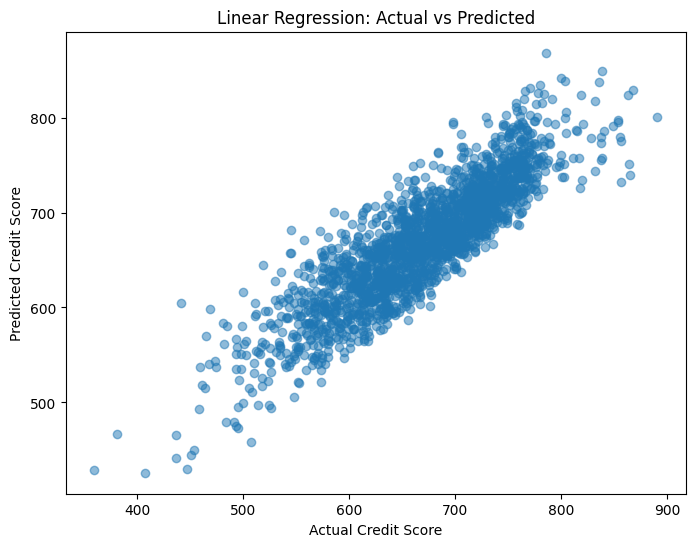

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.5)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()

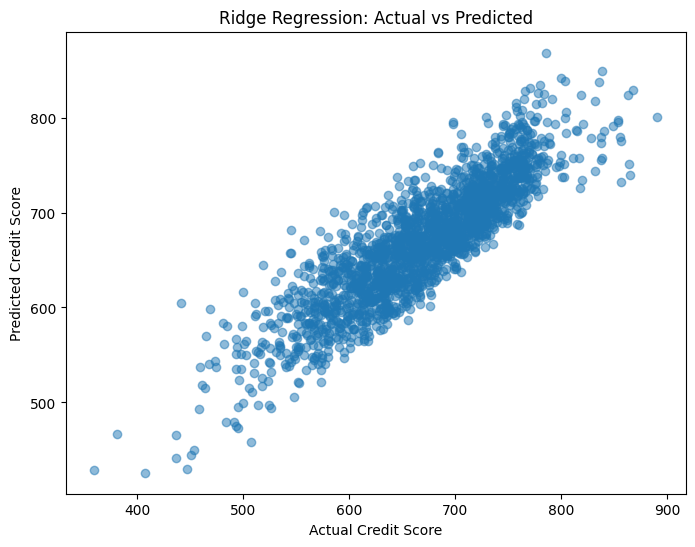

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_ridge, alpha=0.5)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("Ridge Regression: Actual vs Predicted")

plt.show()

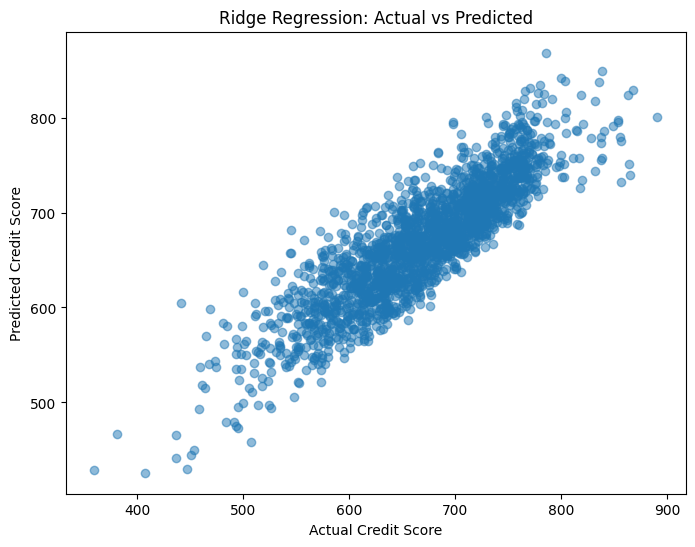

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_ridge, alpha=0.5)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("Ridge Regression: Actual vs Predicted")

plt.show()

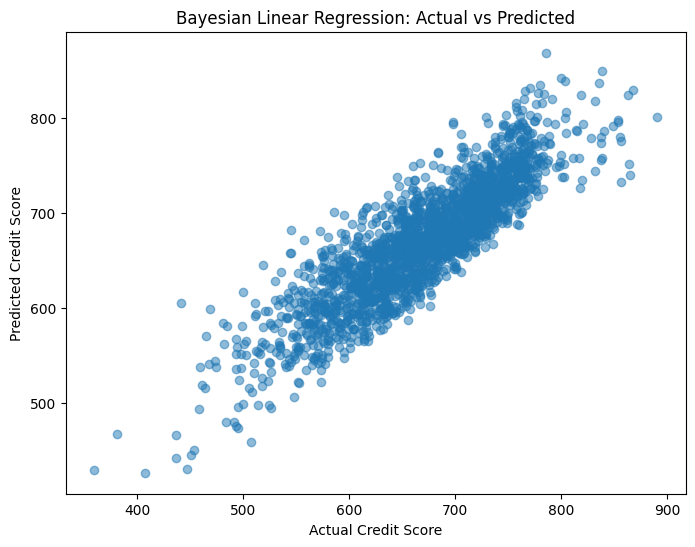

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_bayesian, alpha=0.5)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("Bayesian Linear Regression: Actual vs Predicted")

plt.show()

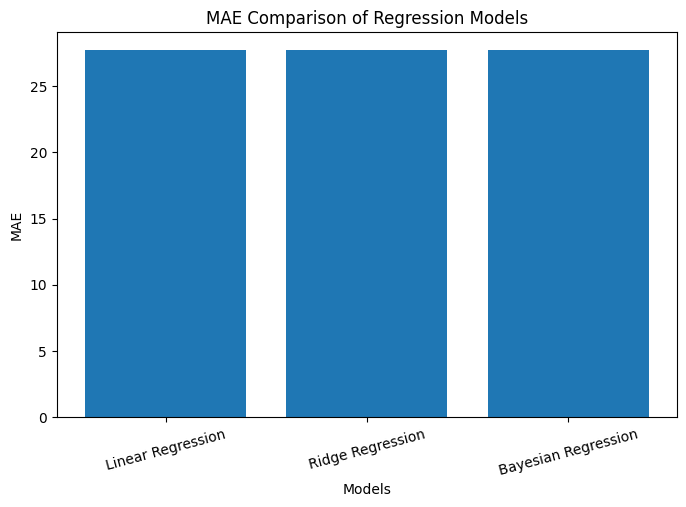

In [ ]:
import matplotlib.pyplot as plt

models = ["Linear Regression", "Ridge Regression", "Bayesian Regression"]

mae_values = [mae, mae_ridge, mae_bayesian]

plt.figure(figsize=(8, 5))

plt.bar(models, mae_values)

plt.xlabel("Models")
plt.ylabel("MAE")
plt.title("MAE Comparison of Regression Models")

plt.xticks(rotation=15)

plt.show()

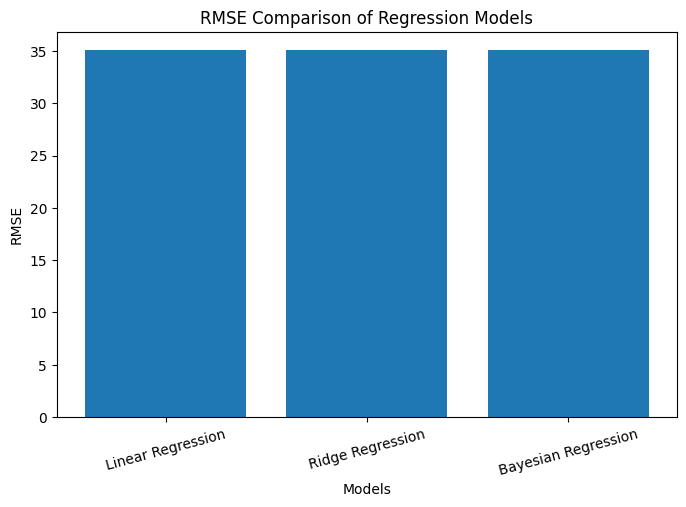

In [ ]:
import matplotlib.pyplot as plt

models = ["Linear Regression", "Ridge Regression", "Bayesian Regression"]

rmse_values = [rmse, rmse_ridge, rmse_bayesian]

plt.figure(figsize=(8, 5))

plt.bar(models, rmse_values)

plt.xlabel("Models")
plt.ylabel("RMSE")
plt.title("RMSE Comparison of Regression Models")

plt.xticks(rotation=15)

plt.show()

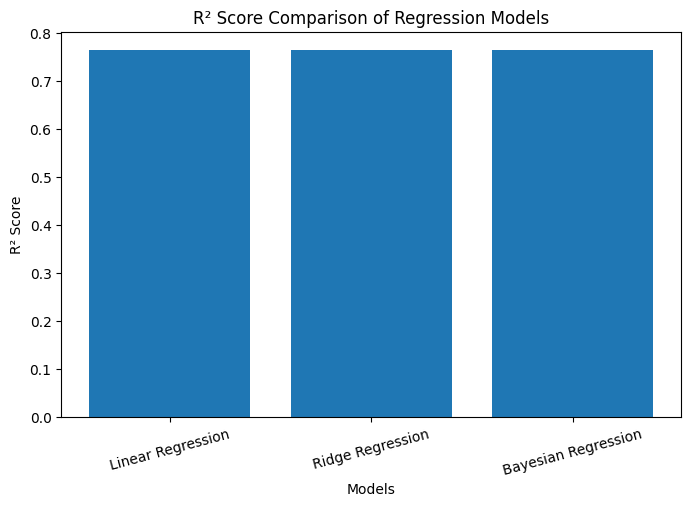

In [ ]:
import matplotlib.pyplot as plt

models = ["Linear Regression", "Ridge Regression", "Bayesian Regression"]

r2_values = [r2, r2_ridge, r2_bayesian]

plt.figure(figsize=(8, 5))

plt.bar(models, r2_values)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("R² Score Comparison of Regression Models")

plt.xticks(rotation=15)

plt.show()

In [ ]:
from sklearn.svm import SVR

svr_model = SVR(kernel="rbf")

svr_model.fit(
    X_train_scaled,
    y_train
)

print("Support Vector Regression training completed!")

Support Vector Regression training completed!


In [ ]:
y_pred_svr = svr_model.predict(X_test_scaled)

print("First 10 actual scores:")
print(y_test.iloc[:10].values)

print("\nFirst 10 SVR predictions:")
print(y_pred_svr[:10])

First 10 actual scores:
[836 715 740 756 691 763 652 577 632 742]

First 10 SVR predictions:
[771.78105629 693.32143746 733.00535381 761.518411   648.09107004
 716.8942561  662.42244956 607.46210194 645.54367963 705.04122148]


In [ ]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)

rmse_svr = np.sqrt(
    mean_squared_error(y_test, y_pred_svr)
)

r2_svr = r2_score(
    y_test,
    y_pred_svr
)

print("SVR MAE :", mae_svr)
print("SVR RMSE:", rmse_svr)
print("SVR R²  :", r2_svr)

SVR MAE : 27.643886419839497
SVR RMSE: 38.44974353298855
SVR R²  : 0.7163865734052791


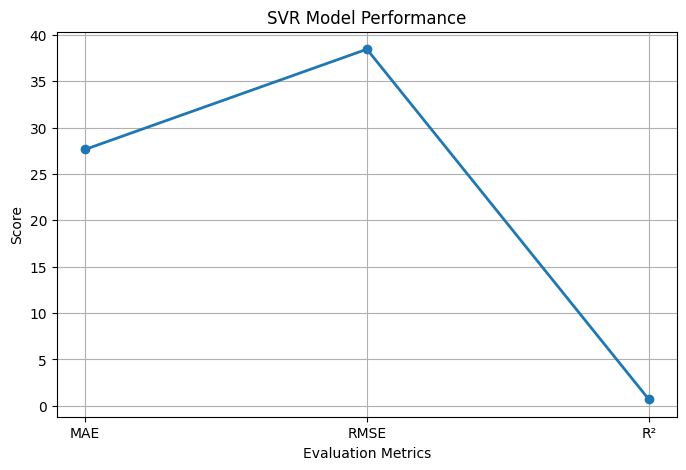

In [ ]:
import matplotlib.pyplot as plt

metrics = ["MAE", "RMSE", "R²"]
values = [mae_svr, rmse_svr, r2_svr]

plt.figure(figsize=(8, 5))

plt.plot(metrics, values, marker="o", linewidth=2)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("SVR Model Performance")

plt.grid(True)
plt.show()

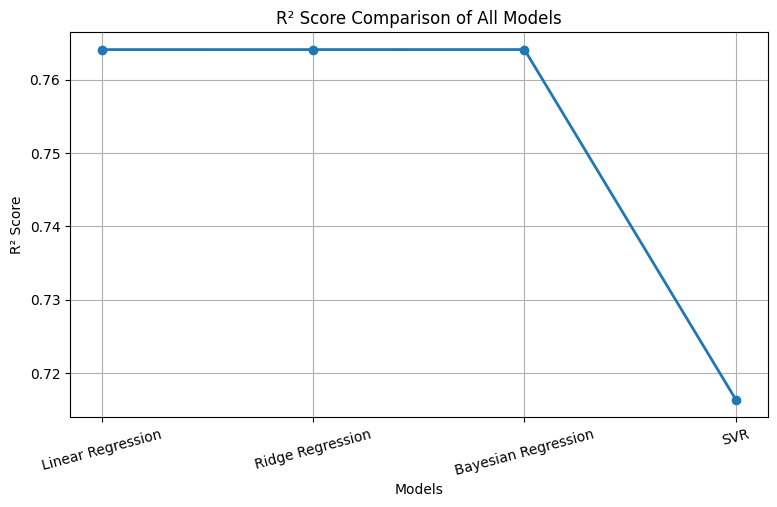

In [ ]:
import matplotlib.pyplot as plt

models = [
    "Linear Regression",
    "Ridge Regression",
    "Bayesian Regression",
    "SVR"
]

r2_values = [
    r2,
    r2_ridge,
    r2_bayesian,
    r2_svr
]

plt.figure(figsize=(9, 5))

plt.plot(
    models,
    r2_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("R² Score Comparison of All Models")

plt.grid(True)
plt.xticks(rotation=15)

plt.show()

In [ ]:
def credit_category(score):
    if score < 580:
        return "Poor"
    elif score < 670:
        return "Fair"
    elif score < 740:
        return "Good"
    else:
        return "Excellent"


y_class = df["credit_score"].apply(credit_category)

print(y_class.value_counts())

credit_score
Fair         3678
Good         3644
Excellent    1623
Poor         1055
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_svm = X
y_svm = y_class

X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X_svm,
    y_svm,
    test_size=0.20,
    random_state=42,
    stratify=y_svm
)

print("Training data:", X_train_svm.shape)
print("Testing data:", X_test_svm.shape)

Training data: (8000, 18)
Testing data: (2000, 18)


In [ ]:
from sklearn.preprocessing import StandardScaler

svm_scaler = StandardScaler()

X_train_svm_scaled = svm_scaler.fit_transform(X_train_svm)
X_test_svm_scaled = svm_scaler.transform(X_test_svm)

print("SVM data scaling completed!")

SVM data scaling completed!


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(
    X_train_svm_scaled,
    y_train_svm
)

print("SVM Classifier training completed!")

SVM Classifier training completed!


In [ ]:
y_pred_svm = svm_model.predict(X_test_svm_scaled)

print("First 10 actual classes:")
print(y_test_svm.iloc[:10].values)

print("\nFirst 10 predicted classes:")
print(y_pred_svm[:10])

First 10 actual classes:
['Poor' 'Fair' 'Good' 'Fair' 'Fair' 'Good' 'Excellent' 'Good' 'Fair'
 'Good']

First 10 predicted classes:
['Poor' 'Good' 'Good' 'Fair' 'Fair' 'Fair' 'Excellent' 'Fair' 'Fair'
 'Good']


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_svm = accuracy_score(y_test_svm, y_pred_svm)

precision_svm = precision_score(
    y_test_svm,
    y_pred_svm,
    average="weighted"
)

recall_svm = recall_score(
    y_test_svm,
    y_pred_svm,
    average="weighted"
)

f1_svm = f1_score(
    y_test_svm,
    y_pred_svm,
    average="weighted"
)

print("SVM Accuracy :", accuracy_svm)
print("SVM Precision:", precision_svm)
print("SVM Recall   :", recall_svm)
print("SVM F1 Score :", f1_svm)

SVM Accuracy : 0.787
SVM Precision: 0.7909447846450222
SVM Recall   : 0.787
SVM F1 Score : 0.7848667845032813


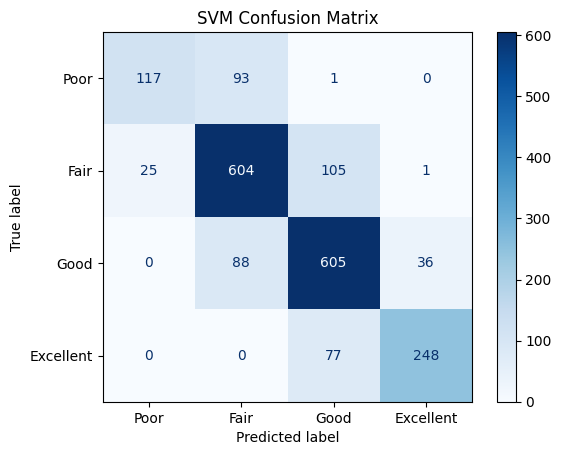

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_test_svm,
    y_pred_svm,
    labels=["Poor", "Fair", "Good", "Excellent"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Poor", "Fair", "Good", "Excellent"]
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.show()

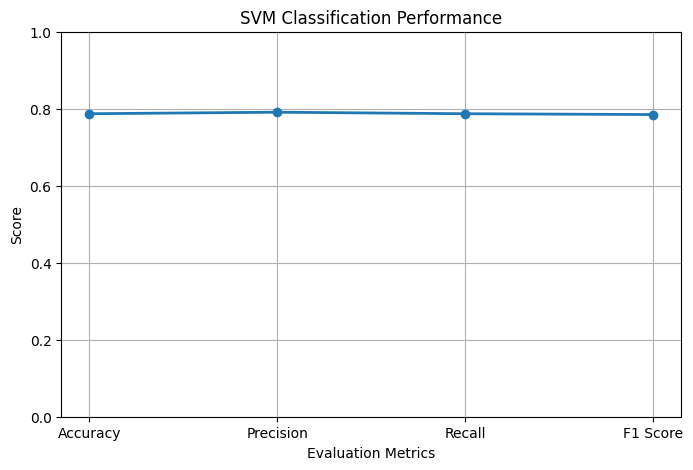

In [ ]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

values = [
    accuracy_svm,
    precision_svm,
    recall_svm,
    f1_svm
]

plt.figure(figsize=(8, 5))

plt.plot(
    metrics,
    values,
    marker="o",
    linewidth=2
)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("SVM Classification Performance")

plt.ylim(0, 1)
plt.grid(True)

plt.show()

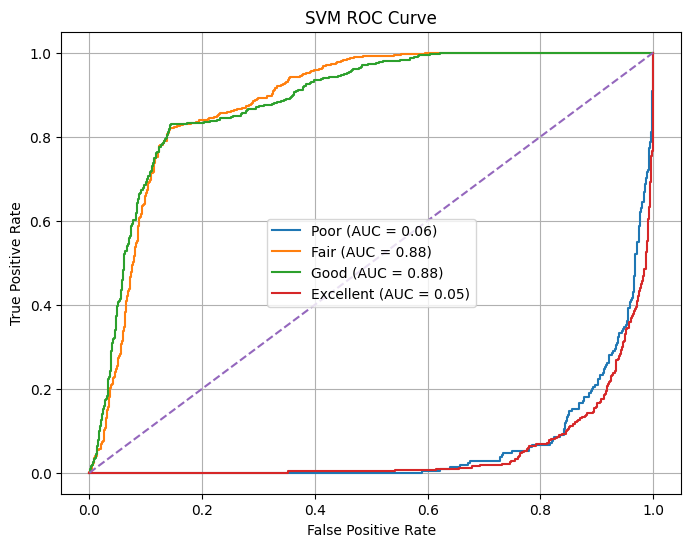

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = ["Poor", "Fair", "Good", "Excellent"]

y_test_binary = label_binarize(
    y_test_svm,
    classes=classes
)

y_score = svm_model.decision_function(X_test_svm_scaled)

plt.figure(figsize=(8, 6))

for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{classes[i]} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curve")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_svm,
    y_pred_svm
))

              precision    recall  f1-score   support

   Excellent       0.87      0.76      0.81       325
        Fair       0.77      0.82      0.79       735
        Good       0.77      0.83      0.80       729
        Poor       0.82      0.55      0.66       211

    accuracy                           0.79      2000
   macro avg       0.81      0.74      0.77      2000
weighted avg       0.79      0.79      0.78      2000



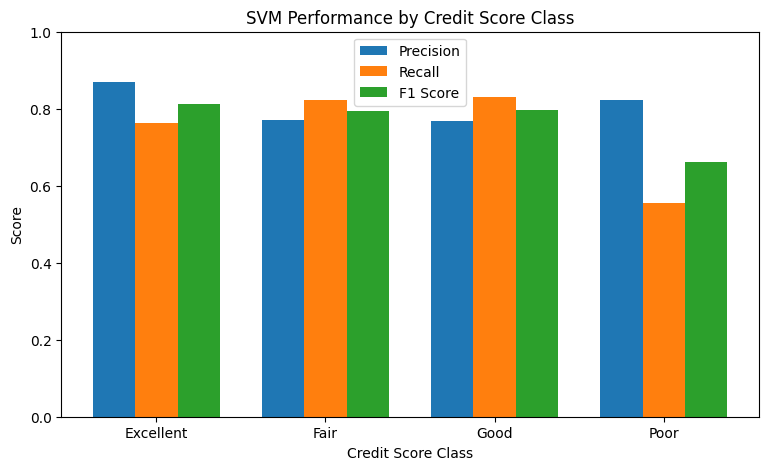

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt
import numpy as np

classes = ["Excellent", "Fair", "Good", "Poor"]

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test_svm,
    y_pred_svm,
    labels=classes
)

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(9, 5))

plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1, width, label="F1 Score")

plt.xlabel("Credit Score Class")
plt.ylabel("Score")
plt.title("SVM Performance by Credit Score Class")

plt.xticks(x, classes)
plt.ylim(0, 1)
plt.legend()

plt.show()

In [ ]:
import pandas as pd

predicted_counts = pd.Series(y_pred_svm).value_counts()

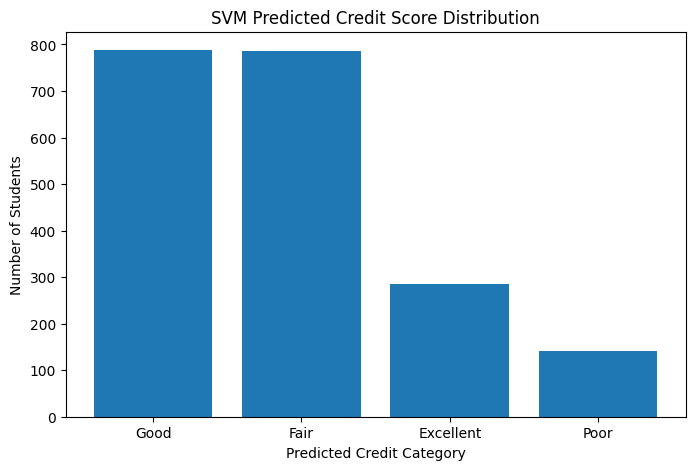

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

predicted_counts = pd.Series(y_pred_svm).value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    predicted_counts.index,
    predicted_counts.values
)

plt.xlabel("Predicted Credit Category")
plt.ylabel("Number of Students")
plt.title("SVM Predicted Credit Score Distribution")

plt.show()